# PSO, Random Search and Hill Climbing

Member 3 (TV3) · CS420 Seminar S01

Run all cells in order. In a local checkout, the notebook locates TV2's `results_pso.csv` automatically. In Colab, upload the CSV to the session before running. If the CSV is absent, the notebook regenerates the TV2 histories using the copied implementation. Outputs are written to the TV3 folder in the checkout or the session directory in Colab.

- **3.1** Run the baselines with the same objective-evaluation budget as TV2.
- **3.2** Compare default PSO with the baselines on two objectives.
- **3.3** Run a separate 20-seed diagnostic for premature convergence.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BOUNDS = (-5.12, 5.12)
DIM, VMAX = 2, 10.24
W_DEFAULT, C1_DEFAULT, C2_DEFAULT = 0.7, 1.5, 1.5
N_PARTICLES, N_ITER = 20, 100
BUDGET = N_PARTICLES * (N_ITER + 1)
SEEDS = range(5)
CONFIGS = {"A": 0.4, "B": 0.7, "C": 0.9}
HC_SIGMA = 0.3
TARGET = 0.01

cwd = Path.cwd()
tv3_dir = cwd / "03_TV3_ThucNghiem"
out_dir = tv3_dir if tv3_dir.is_dir() else cwd
fig_dir = out_dir / "figures"
fig_dir.mkdir(exist_ok=True)
csv_paths = [out_dir.parent / "02_TV2_MoPhong" / "results_pso.csv", cwd / "results_pso.csv"]
pso_csv = next((path for path in csv_paths if path.is_file()), None)

The objective functions and `pso()` below are copied from TV2's `PSO_Seminar.ipynb`. PSO reports one observation per swarm batch. The initialization is the first batch of 20 evaluations.

In [2]:
def sphere(X):
    # Sphere: f(x) = sum_i x_i^2. Accepts one point (d,) or a batch (n, d).
    X = np.asarray(X, dtype=float)
    return np.sum(X ** 2, axis=-1)


def rastrigin(X):
    # Rastrigin: f(x) = 10 n + sum_i (x_i^2 - 10 cos(2 pi x_i)). Many local minima, global minimum 0 at the origin.
    X = np.asarray(X, dtype=float)
    n = X.shape[-1]
    return 10 * n + np.sum(X ** 2 - 10 * np.cos(2 * np.pi * X), axis=-1)


FUNCTIONS = {"Sphere": sphere, "Rastrigin": rastrigin}

# Sanity checks: both functions are 0 at the global minimum (0, 0)
assert sphere([0.0, 0.0]) == 0.0
assert abs(rastrigin([0.0, 0.0])) < 1e-12
print("sphere(0,0) =", sphere([0.0, 0.0]), "| rastrigin(0,0) =", rastrigin([0.0, 0.0]))
print("sphere(1,2) =", sphere([1.0, 2.0]), "| rastrigin(1,1) =", rastrigin([1.0, 1.0]))

sphere(0,0) = 0.0 | rastrigin(0,0) = 0.0
sphere(1,2) = 5.0 | rastrigin(1,1) = 2.0


In [3]:
def pso(func, n_particles=N_PARTICLES, n_iter=N_ITER, w=W_DEFAULT, c1=C1_DEFAULT, c2=C2_DEFAULT,
        bounds=BOUNDS, vmax=VMAX, seed=0, dim=DIM, log_states=False):
    # Global-best PSO (gbest topology), minimisation.
    #   v(t+1) = w v(t) + c1 r1 (pbest - x(t)) + c2 r2 (gbest - x(t))
    #   x(t+1) = x(t) + v(t+1)
    # r1, r2 ~ U(0, 1) are drawn per particle, per dimension, per iteration.
    rng = np.random.default_rng(seed)
    lo, hi = bounds

    # Initialisation: positions uniform in the domain, velocities uniform in [-vmax, vmax]
    x = rng.uniform(lo, hi, size=(n_particles, dim))
    v = rng.uniform(-vmax, vmax, size=(n_particles, dim))
    f = func(x)
    evaluations = n_particles

    pbest, pbest_f = x.copy(), f.copy()          # personal bests
    g = int(np.argmin(pbest_f))
    gbest, gbest_f = pbest[g].copy(), float(pbest_f[g])   # global best

    history = [{"iteration": 0, "evaluations": evaluations, "best_fitness": gbest_f}]
    states = []
    if log_states:
        states.append({"iteration": 0, "x": x.copy(), "v": v.copy(), "f": f.copy(),
                       "pbest": pbest.copy(), "pbest_f": pbest_f.copy(),
                       "gbest": gbest.copy(), "gbest_f": gbest_f, "r1": None, "r2": None})

    for t in range(1, n_iter + 1):
        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))
        gbest_used = gbest.copy()                 # gbest of the previous iteration drives this update

        # Velocity update (inertia + cognitive + social), then clamp to [-vmax, vmax]
        v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest_used - x)
        v = np.clip(v, -vmax, vmax)

        # Position update with the NEW velocity, then clip to the domain
        x = np.clip(x + v, lo, hi)

        f = func(x)
        evaluations += n_particles

        # Update personal bests where the new position is strictly better
        improved = f < pbest_f
        pbest[improved] = x[improved]
        pbest_f[improved] = f[improved]

        # Update global best
        g = int(np.argmin(pbest_f))
        if pbest_f[g] < gbest_f:
            gbest, gbest_f = pbest[g].copy(), float(pbest_f[g])

        history.append({"iteration": t, "evaluations": evaluations, "best_fitness": gbest_f})
        if log_states:
            states.append({"iteration": t, "x": x.copy(), "v": v.copy(), "f": f.copy(),
                           "pbest": pbest.copy(), "pbest_f": pbest_f.copy(),
                           "gbest": gbest.copy(), "gbest_f": gbest_f,
                           "r1": r1.copy(), "r2": r2.copy(), "gbest_used": gbest_used})

    return {"history": pd.DataFrame(history), "best_x": gbest, "best_f": gbest_f,
            "evaluations": evaluations, "states": states}

## 3.1 · Baselines

Random Search independently samples 2,020 points uniformly in the box and retains the best. Hill Climbing uses one uniform start and proposes 2,019 local steps with independent Gaussian noise of standard deviation 0.3 per coordinate. Each candidate is clipped to the box and evaluated once. The search moves only on a strict improvement and uses no restarts. The objective wrapper counts actual calls, including initialization and rejected proposals.

In [4]:
def random_search(func, bounds, budget, seed):
    rng = np.random.default_rng(seed)
    candidates = rng.uniform(*bounds, size=(budget, DIM))
    scores = np.array([func(candidate) for candidate in candidates])
    return np.minimum.accumulate(scores)


def hill_climbing(func, bounds, budget, sigma, seed):
    rng = np.random.default_rng(seed)
    current = rng.uniform(*bounds, size=DIM)
    score = float(func(current))
    history = np.empty(budget)
    history[0] = score
    for i in range(1, budget):
        candidate = np.clip(current + rng.normal(0, sigma, size=DIM), *bounds)
        candidate_score = float(func(candidate))
        if candidate_score < score:
            current, score = candidate, candidate_score
        history[i] = score
    return history


def counted_objective(func):
    counts = {"calls": 0, "evaluations": 0}

    def evaluate(points):
        counts["calls"] += 1
        counts["evaluations"] += len(np.atleast_2d(points))
        return func(points)

    return evaluate, counts


# A scalar call evaluates one point. TV2's vectorized PSO call evaluates one swarm.
records = []
for function, func in FUNCTIONS.items():
    for seed in SEEDS:
        for method, run, options in [
            ("Random Search", random_search, {}),
            ("Hill Climbing", hill_climbing, {"sigma": HC_SIGMA}),
        ]:
            objective, counts = counted_objective(func)
            history = run(objective, BOUNDS, BUDGET, seed=seed, **options)
            assert counts == {"calls": BUDGET, "evaluations": BUDGET}
            assert len(history) == BUDGET and np.isfinite(history).all()
            assert (np.diff(history) <= 0).all()
            records.append(pd.DataFrame({
                "function": function, "method": method, "seed": seed,
                "evaluations": np.arange(1, BUDGET + 1), "best_fitness": history,
            }))

baseline = pd.concat(records, ignore_index=True)
assert len(baseline) == len(FUNCTIONS) * 2 * len(SEEDS) * BUDGET
baseline.to_csv(out_dir / "results_baseline.csv", index=False)
print(f"{len(baseline):,} baseline observations written. Each run used {BUDGET:,} objective calls.")

40,400 baseline observations written. Each run used 2,020 objective calls.


## 3.2 · Equal-budget comparison

Read the exported baseline and TV2 histories. Replay the full TV2 inertia sweep to verify the handoff, then use only configuration B (ω = 0.7) for the baseline comparison. Plot all three methods at common checkpoints (20, 40, …, 2,020 evaluations). For the first-hit table, use the finest available recording frequency: one evaluation for each baseline and one 20-point swarm batch for PSO. Report the mean over successful seeds and the number of hits, so runs that never reach the target remain visible.

In [5]:
def checked_pso(func, w, seed):
    objective, counts = counted_objective(func)
    result = pso(objective, w=w, seed=seed)
    assert counts == {"calls": N_ITER + 1, "evaluations": BUDGET}
    return result["history"]


replay = pd.concat([
    checked_pso(func, w, seed).assign(
        function=function, config=config, w=w, c1=C1_DEFAULT, c2=C2_DEFAULT, seed=seed
    )
    for function, func in FUNCTIONS.items()
    for config, w in CONFIGS.items()
    for seed in SEEDS
], ignore_index=True)
keys = ["function", "config", "seed", "iteration"]
replay = replay.set_index(keys).sort_index()
if pso_csv is None:
    pso_results = replay
    print("TV2 CSV unavailable. Using the regenerated PSO histories.")
else:
    pso_results = pd.read_csv(pso_csv, float_precision="round_trip").set_index(keys).sort_index()
    pd.testing.assert_index_equal(pso_results.index, replay.index)
    for column in ["evaluations", "w", "c1", "c2"]:
        np.testing.assert_array_equal(pso_results[column], replay[column])
    for function, atol in {"Sphere": 1e-40, "Rastrigin": 5e-14}.items():
        np.testing.assert_allclose(
            pso_results.loc[function, "best_fitness"], replay.loc[function, "best_fitness"],
            rtol=1e-9, atol=atol,
        )
    print(f"Verified {len(pso_results):,} TV2 observations against {pso_csv.name}.")

baseline = pd.read_csv(out_dir / "results_baseline.csv", float_precision="round_trip")
pso_long = pso_results.reset_index()
pso_long = pso_long[pso_long["config"] == "B"].assign(method="PSO B")
columns = baseline.columns.tolist()
full_history = pd.concat([pso_long[columns], baseline], ignore_index=True)
checkpoints = np.arange(N_PARTICLES, BUDGET + 1, N_PARTICLES)
comparison = full_history[full_history["evaluations"].isin(checkpoints)]

for _, run in comparison.groupby(["function", "method", "seed"]):
    np.testing.assert_array_equal(run["evaluations"], checkpoints)
    assert np.isfinite(run["best_fitness"]).all()
    assert (np.diff(run["best_fitness"]) <= 0).all()

final = comparison.loc[comparison["evaluations"] == BUDGET]
summary = final.groupby(["function", "method"], sort=False).agg(
    mean=("best_fitness", "mean"),
    sd=("best_fitness", "std"),
    best=("best_fitness", "min"),
    worst=("best_fitness", "max"),
)
assert final.groupby(["function", "method"])["seed"].nunique().eq(len(SEEDS)).all()

first_hit = (
    full_history[full_history["best_fitness"] < TARGET]
    .groupby(["function", "method", "seed"])["evaluations"].min()
)
target_summary = first_hit.groupby(["function", "method"]).agg(["mean", "count"]).reindex(summary.index)
target_summary["count"] = target_summary["count"].fillna(0).astype(int)
target_summary["mean"] = target_summary["mean"].map(
    lambda value: "Not reached" if pd.isna(value) else f"{value:.1f}"
)
target_summary.columns = ["mean_evaluations_to_target", "seeds_reaching_target"]
print(summary.to_string(float_format=lambda value: f"{value:.6e}"))
print(f"First checkpoint below {TARGET}:")
print(target_summary.to_string())

Verified 3,030 TV2 observations against results_pso.csv.
                                mean           sd         best        worst
function  method                                                           
Rastrigin PSO B         1.069680e-06 2.344839e-06 1.595168e-11 5.263974e-06
Sphere    PSO B         1.004329e-12 1.249965e-12 1.502165e-15 2.432829e-12
          Random Search 1.397198e-02 1.605085e-02 1.216406e-03 4.153807e-02
          Hill Climbing 2.601686e-04 2.882704e-04 4.340570e-05 6.465942e-04
Rastrigin Random Search 1.231757e+00 8.267858e-01 2.408018e-01 2.484235e+00
          Hill Climbing 5.204732e+00 4.557352e+00 1.990891e+00 1.303658e+01
First checkpoint below 0.01:
                        mean_evaluations_to_target  seeds_reaching_target
function  method                                                         
Rastrigin PSO B                             1004.0                      5
Sphere    PSO B                              216.0                      5
          

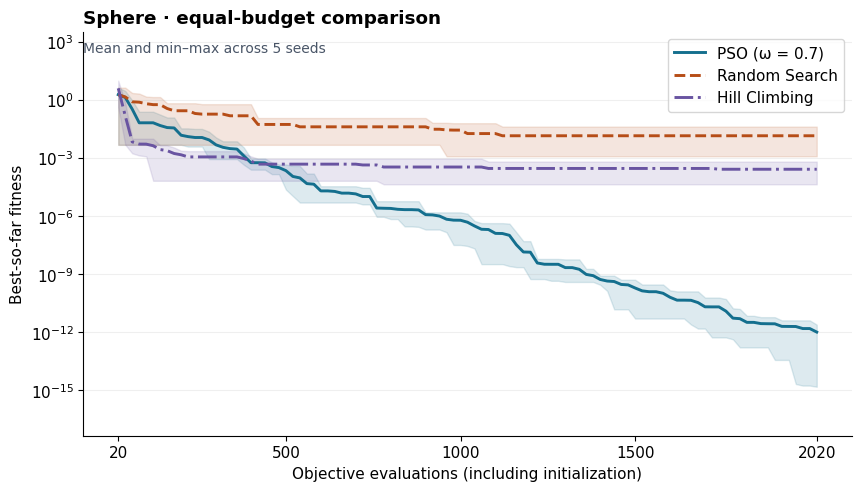

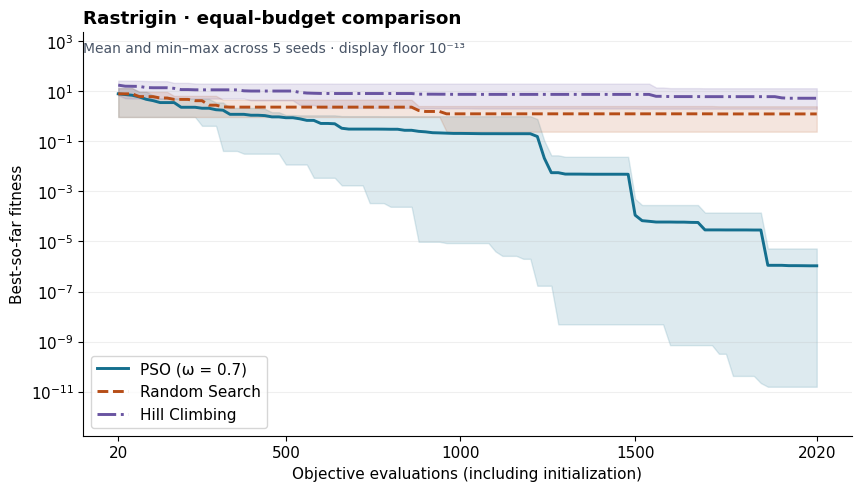

In [6]:
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "figure.facecolor": "white",
})
plot_methods = [
    ("PSO B", "PSO (ω = 0.7)", "#146F8E", "-"),
    ("Random Search", "Random Search", "#B64D17", "--"),
    ("Hill Climbing", "Hill Climbing", "#6954A1", "-."),
]

for function in FUNCTIONS:
    floor = 1e-13 if function == "Rastrigin" else None
    fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
    for method, label, color, style in plot_methods:
        subset = comparison[(comparison["function"] == function) & (comparison["method"] == method)]
        curve = subset.groupby("evaluations")["best_fitness"].agg(["mean", "min", "max"])
        if floor is not None:
            curve = curve.clip(lower=floor)
        ax.plot(curve.index, curve["mean"], color=color, ls=style, lw=2.1, label=label)
        ax.fill_between(curve.index, curve["min"], curve["max"], color=color, alpha=0.14)
    ax.set_yscale("log")
    ax.set_xlabel("Objective evaluations (including initialization)")
    ax.set_ylabel("Best-so-far fitness")
    ax.set_xticks([20, 500, 1000, 1500, BUDGET])
    ax.set_title(f"{function} · equal-budget comparison", loc="left")
    subtitle = "Mean and min–max across 5 seeds"
    if floor is not None:
        subtitle += " · display floor 10⁻¹³"
    ax.text(0.0, 0.975, subtitle, transform=ax.transAxes, va="top", color="#495567", fontsize=10)
    ax.margins(y=0.16)
    ax.grid(axis="y", alpha=0.2)
    legend_position = "lower left" if function == "Rastrigin" else "upper right"
    ax.legend(loc=legend_position, frameon=True)
    fig.savefig(fig_dir / f"fig_compare_{function.lower()}.png", dpi=180)
    plt.show()

## 3.3 · A local-optimum case on Rastrigin

Sweep seeds 0–19 with 5 particles, 100 iterations, ω = 0.4, c₁ = 0.5 and c₂ = 2.5. Select the first seed with final fitness above 0.9 and independently verify the basin. Compare it with the default run at the same seed. The small swarm uses 505 evaluations and the default swarm uses 2,020, so this comparison illustrates behavior over iterations.

In [7]:
trap_settings = {"n_particles": 5, "w": 0.4, "c1": 0.5, "c2": 2.5}
sweep = pd.Series({
    seed: pso(rastrigin, seed=seed, **trap_settings)["best_f"]
    for seed in range(20)
}, name="final_best_fitness").rename_axis("seed")
print(sweep.to_string(float_format=lambda value: f"{value:.9g}"))
sweep.to_csv(out_dir / "diagnostic_sweep.csv")

eligible = sweep[sweep > 0.9]
trap_seed = None if eligible.empty else int(eligible.index[0])
if trap_seed is None:
    print("No seed ended above 0.9. Adjust the diagnostic settings and rerun the sweep.")


def derivative(u):
    return 2 * u + 20 * np.pi * np.sin(2 * np.pi * u)


def basin_minimum(integer):
    lo, hi = integer - 0.1, integer + 0.1
    assert derivative(lo) < 0 < derivative(hi)
    for _ in range(50):
        mid = (lo + hi) / 2
        if derivative(mid) < 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def centroid_distance(state):
    positions = state["x"]
    return np.linalg.norm(positions - positions.mean(axis=0), axis=1).mean()


if trap_seed is not None:
    trap = pso(rastrigin, seed=trap_seed, log_states=True, **trap_settings)
    default = pso(rastrigin, seed=trap_seed, log_states=True)
    assert trap["best_f"] == sweep.loc[trap_seed]
    assert trap["evaluations"] == 505 and default["evaluations"] == BUDGET

    # Rastrigin is separable. Verify positive curvature along both axes.
    local_x = np.array([basin_minimum(i) for i in np.rint(trap["best_x"])])
    local_f = float(rastrigin(local_x))
    assert np.all(2 + 40 * np.pi**2 * np.cos(2 * np.pi * local_x) > 0)
    assert local_f > rastrigin([0.0, 0.0])
    np.testing.assert_allclose(trap["best_x"], local_x, atol=1e-6, rtol=0)
    assert abs(float(rastrigin(trap["best_x"])) - local_f) < 1e-12

    print(f"Selected seed {trap_seed}: final best {trap['best_x']}, fitness {trap['best_f']:.12g}")
    print(f"Nearby local minimum: {local_x}, fitness {local_f:.12g}")
    print(f"Default PSO: final best {default['best_x']}, fitness {default['best_f']:.12g}")
    trace = pd.DataFrame({
        "iteration": trap["history"]["iteration"],
        "diagnostic_fitness": trap["history"]["best_fitness"],
        "default_fitness": default["history"]["best_fitness"],
        "diagnostic_diversity": [centroid_distance(state) for state in trap["states"]],
        "default_diversity": [centroid_distance(state) for state in default["states"]],
    })
    trace.to_csv(out_dir / f"diagnostic_trace_seed{trap_seed}.csv", index=False)
    print(trace.iloc[[0, 10, 50, 100]].to_string(index=False))

seed
0    0.994959057
1    0.994959057
2    0.994959057
3     4.97479025
4    0.994959057
5     1.98991815
6     3.97983119
7     3.97983119
8     12.9344324
9     4.97479025
10   0.994959057
11    1.98991811
12    4.97479025
13    7.95966238
14    4.97479025
15    1.98991811
16   0.994959057
17    4.97479025
18    1.98991811
19    4.97479025
Selected seed 0: final best [ 6.71716286e-10 -9.94958635e-01], fitness 0.994959057093
Nearby local minimum: [-8.88178420e-17 -9.94958638e-01], fitness 0.994959057093
Default PSO: final best [5.73723811e-07 8.87729121e-06], fitness 1.5699846756e-08
 iteration  diagnostic_fitness  default_fitness  diagnostic_diversity  default_diversity
         0           24.218210     9.480294e+00          4.183873e+00           3.826593
        10            6.465620     4.864798e+00          1.140864e+00           1.736347
        50            0.994960     9.111884e-03          8.933802e-05           0.770176
       100            0.994959     1.569985e-08    

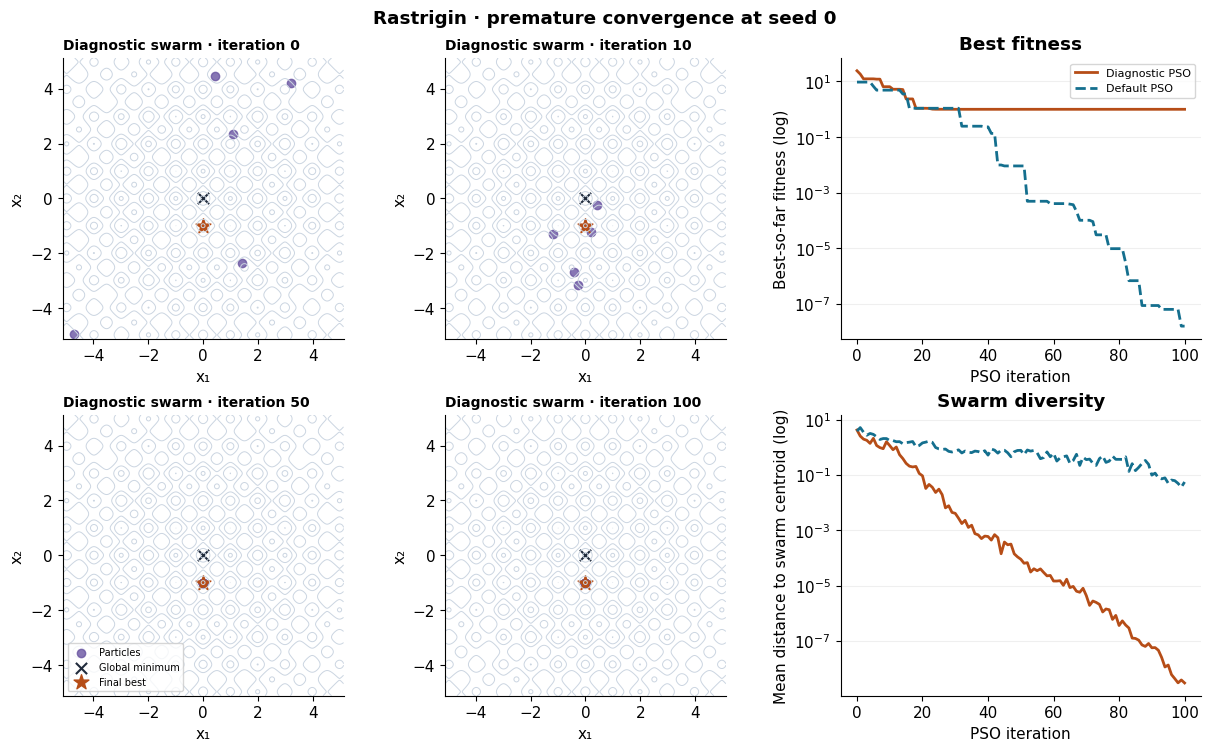

In [8]:
if trap_seed is not None:
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.4), layout="constrained")
    grid = np.linspace(*BOUNDS, 450)
    gx, gy = np.meshgrid(grid, grid)
    surface = rastrigin(np.stack((gx, gy), axis=-1))
    checkpoints = [0, 10, 50, 100]
    for ax, iteration in zip(axes[:, :2].flat, checkpoints):
        state = trap["states"][iteration]
        ax.contour(gx, gy, surface, levels=[2, 10, 20, 30, 45, 65], colors="#CBD5E1", linewidths=0.7)
        ax.scatter(*state["x"].T, color="#6954A1", s=36, alpha=0.8, label="Particles")
        ax.scatter(0, 0, marker="x", s=65, color="#202B3C", label="Global minimum")
        ax.scatter(*trap["best_x"], marker="*", s=125, color="#B64D17", label="Final best")
        ax.set(xlim=BOUNDS, ylim=BOUNDS, xlabel="x₁", ylabel="x₂", aspect="equal")
        ax.set_title(f"Diagnostic swarm · iteration {iteration}", loc="left", fontsize=10)

    for ax, metric, ylabel, title in [
        (axes[0, 2], "fitness", "Best-so-far fitness (log)", "Best fitness"),
        (axes[1, 2], "diversity", "Mean distance to swarm centroid (log)", "Swarm diversity"),
    ]:
        for label, color, style in [("diagnostic", "#B64D17", "-"), ("default", "#146F8E", "--")]:
            values = trace[f"{label}_{metric}"]
            if metric == "fitness":
                values = values.clip(lower=1e-13)
            ax.plot(trace["iteration"], values, color=color, ls=style, lw=2, label=f"{label.title()} PSO")
        ax.set(xlabel="PSO iteration", ylabel=ylabel, yscale="log", title=title)
        ax.grid(axis="y", alpha=0.2)
    axes[0, 2].legend(loc="upper right", fontsize=8)
    axes[1, 0].legend(loc="lower left", fontsize=7)
    fig.suptitle(f"Rastrigin · premature convergence at seed {trap_seed}", fontweight="bold")
    fig.savefig(fig_dir / "fig_local_optimum.png", dpi=180)
    plt.show()